# Evaluation

I den här notebooken utvärderas projektets två metoder för kompetensidentifiering:
**Baseline** och **EntityRuler**.

Båda metoderna testas på samma manuellt annoterade test-set.
Baseline utvärderas både mot endast taxonomikompetenser och mot samtliga
annoterade kompetenser. EntityRuler utvärderas mot samtliga annoterade
kompetenser.
Metoderna jämförs med **precision, recall och F1-score** samt genom
felanalys av false positives och false negatives.

Test-setet har inte använts vid utvecklingen av regler eller synonymer.

In [ ]:
# importer
import json
import pandas as pd

from src.models import (
    baseline_extract_skills,
    build_nlp,
    entity_ruler_extract_skills
)

from src.skill_rules import (
    TIER1_PHRASES,
    TIER2_EXACT_CASE,
    TIER3_CUSTOM
)

from src.evaluation_utils import (
    build_alias_to_canonical,
    normalize_skills,
    calculate_metrics,
    create_error_analysis
)

## Läser in annoterat test-set

`annoterad_test_data.json` innehåller både jobbannonserna från test-setet
och de manuellt annoterade kompetenserna.

Datan används därför både för att skapa test-setet och som facit
(gold standard) vid utvärderingen.

In [4]:
with open(
    "../data/annoterad_test_data.json",
    "r",
    encoding="utf-8"
) as file:
    annotated_data = json.load(file)

print("Antal annoterade annonser:", len(annotated_data))

Antal annoterade annonser: 192


## Skapar test-data

Jobbannonsens ID och annonstext hämtas från den annoterade datan och
läggs i en DataFrame.

Samma annonser kommer användas för både Baseline och EntityRuler.

In [5]:
test_df = pd.DataFrame([
    {
        "id": item["data"]["id"],
        "description": item["data"]["text"]
    }
    for item in annotated_data
])

print("Antal annonser:", len(test_df))
print("Kolumner:", test_df.columns.tolist())

test_df.head()

Antal annonser: 192
Kolumner: ['id', 'description']


,id,description
0,29389255,Vi söker enData PlatformEngineer till uppdrag ...
1,29370869,"Tveka inte, ansök redan idag! Du kan enkelt sk..."
2,29392086,Business Architect (Pega)\nTillsvidareanställn...
3,29413273,Vill du arbeta i en teknologidriven miljö där ...
4,29377922,Techster Solutions befinner i dagsläget sig i ...


## Skapar gold standard

De manuella annotationerna delas upp i två versioner:

- **gold_all_raw** innehåller både `Taxonomi` och `New skill`.
- **gold_taxonomy_raw** innehåller endast `Taxonomi`.

Det gör det möjligt för oss att utvärdera Baseline både inom sitt ursprungliga
taxonomiområde och mot samtliga annoterade kompetenser.

In [6]:
def extract_gold_annotations(annotated_data):
    gold_all = {}
    gold_taxonomy = {}

    for task in annotated_data:
        ad_id = str(task["data"]["id"])

        all_skills = set()
        taxonomy_skills = set()

        for annotation in task.get("annotations", []):
            for result in annotation.get("result", []):
                value = result.get("value", {})

                text = value.get("text")
                labels = value.get("labels", [])

                if not text:
                    continue

                if "Taxonomi" in labels or "New skill" in labels:
                    all_skills.add(text)

                if "Taxonomi" in labels:
                    taxonomy_skills.add(text)

        gold_all[ad_id] = all_skills
        gold_taxonomy[ad_id] = taxonomy_skills

    return gold_all, gold_taxonomy

In [7]:
gold_all_raw, gold_taxonomy_raw = extract_gold_annotations(
    annotated_data
)

print("Antal annonser i gold_all:", len(gold_all_raw))
print("Antal annonser i gold_taxonomy:", len(gold_taxonomy_raw))

Antal annonser i gold_all: 192
Antal annonser i gold_taxonomy: 192


### Gold-data

`gold_all_raw`
= facit med **Taxonomi + New skill**

`gold_taxonomy_raw`
= facit med endast **Taxonomi**

Senare normaliseras dessa så att olika skrivsätt av samma kompetens
kan jämföras med modellernas prediktioner.

### Kontroll av ID

Vi kontrollerar att antalet jobbannonser i test-datan stämmer överens
med antalet annonser i gold standard.

In [8]:
test_ids = set(
    test_df["id"].astype(str)
)

gold_ids = set(
    gold_all_raw.keys()
)

print("Test-set IDs:", len(test_ids))
print("Gold IDs:", len(gold_ids))

print(
    "Saknas i gold:",
    len(test_ids - gold_ids)
)

print(
    "Saknas i test-set:",
    len(gold_ids - test_ids)
)

Test-set IDs: 192
Gold IDs: 192
Saknas i gold: 0
Saknas i test-set: 0


## Baseline

Baseline använder den ursprungliga kompetenslistan från
`skills_2511.json`.

Metoden söker efter kompetensnamnen direkt i annonstexten och använder
inte de nya aliases och synonymer som finns i EntityRuler.

Det gör Baseline till en enklare referensmetod som den förbättrade
EntityRuler-metoden kan jämföras mot.

In [9]:
with open(
    "../data/skills_2511.json",
    "r",
    encoding="utf-8"
) as file:
    skills_data = json.load(file)

skill_names = [
    item["skill"]
    for item in skills_data
]

print("Antal skills i baseline:", len(skill_names))

Antal skills i baseline: 204


In [10]:
test_df["baseline_skills"] = test_df["description"].apply(
    lambda text: baseline_extract_skills(
        text,
        skill_names
    )
)

test_df[
    ["id", "baseline_skills"]
].head()

,id,baseline_skills
0,29389255,[]
1,29370869,[]
2,29392086,[Datamodellering]
3,29413273,[]
4,29377922,[]


### Baseline predictions

Resultaten från Baseline sparas som en dictionary där varje annons-ID
kopplas till de kompetenser som modellen identifierade.

In [11]:
baseline_predictions = {
    str(row["id"]): set(row["baseline_skills"])
    for _, row in test_df.iterrows()
}

list(baseline_predictions.items())[:5]

[('29389255', set()),
 ('29370869', set()),
 ('29392086', {'Datamodellering'}),
 ('29413273', set()),
 ('29377922', set())]

## EntityRuler

EntityRuler använder de regler, aliases och alternativa skrivsätt som
definierats i `skill_rules.py`.

Den färdiga spaCy-pipelinen byggs med funktionen `build_nlp()` från
`models.py`.

In [12]:
nlp = build_nlp()

test_df["entityruler_skills"] = test_df["description"].apply(
    lambda text: entity_ruler_extract_skills(
        text,
        nlp
    )
)

test_df[
    [
        "id",
        "baseline_skills",
        "entityruler_skills"
    ]
].head()

,id,baseline_skills,entityruler_skills
0,29389255,[],"[Databricks, Svenska]"
1,29370869,[],[Artificial Intelligence / Artificiell intelli...
2,29392086,[Datamodellering],"[Datamodellering, ERP-system, erfarenhet, IT-k..."
3,29413273,[],"[Digitalisering, Informatik, Kravhantering]"
4,29377922,[],"[Agile, DevOps, Java, Windows]"


### EntityRuler predictions

Resultaten från EntityRuler sparas i samma format som Baseline-resultaten
så att metoderna senare kan jämföras på samma sätt.

In [13]:
entityruler_predictions = {
    str(row["id"]): set(row["entityruler_skills"])
    for _, row in test_df.iterrows()
}

list(entityruler_predictions.items())[:5]

[('29389255', {'Databricks', 'Svenska'}),
 ('29370869',
  {'Artificial Intelligence / Artificiell intelligens / AI',
   'Automationsteknik',
   'Driva workshops',
   'Engelska',
   'Quality Assurance (QA)',
   'Svenska'}),
 ('29392086',
  {'Datamodellering',
   'ERP-system, erfarenhet',
   'IT-konsultuppdrag, erfarenhet',
   'SQL',
   'Svenska',
   'Verksamhetsanalys'}),
 ('29413273', {'Digitalisering', 'Informatik', 'Kravhantering'}),
 ('29377922', {'Agile', 'DevOps', 'Java', 'Windows'})]

### Data som används i utvärderingen

`gold_all`
= facit med **Taxonomi + New skill**

`gold_taxonomy`
= facit med endast **Taxonomi**

`baseline_predictions`
= kompetenser som Baseline identifierade

`entityruler_predictions`
= kompetenser som EntityRuler identifierade

## Normalisering av gold standard

De manuella annotationerna innehåller den text som faktiskt markerades i
jobbannonsen.

Samma kompetens kan därför förekomma med olika skrivsätt, exempelvis
`LTE` och `4G-teknik`.

För att kunna jämföra annotationerna med EntityRulers canonical
kompetensnamn normaliseras olika aliases till samma standardnamn.

In [14]:
alias_to_canonical = build_alias_to_canonical(
    TIER1_PHRASES,
    TIER2_EXACT_CASE,
    TIER3_CUSTOM
)

print("Antal aliases:", len(alias_to_canonical))

Antal aliases: 1156


In [15]:
# normaliserar gold
gold_all = {
    ad_id: normalize_skills(
        skills,
        alias_to_canonical
    )
    for ad_id, skills in gold_all_raw.items()
}

gold_taxonomy = {
    ad_id: normalize_skills(
        skills,
        alias_to_canonical
    )
    for ad_id, skills in gold_taxonomy_raw.items()
}

In [16]:
# kontorllerar normalisering
example_id = next(iter(gold_all_raw))

print("Före normalisering:")
print(gold_all_raw[example_id])

print("\nEfter normalisering:")
print(gold_all[example_id])

Före normalisering:
{'Azure', 'Dev-Ops-området', ' Azure', 'Databricks'}

Efter normalisering:
{'Azure', 'Dev-Ops-området', 'Databricks'}


## Precision, recall och F1-score

Utvärderingen görs på det manuellt annoterade test-setet.

**Precision** visar hur stor andel av de kompetenser som metoden
identifierade som faktiskt var korrekta.

**Recall** visar hur stor andel av de manuellt annoterade kompetenserna
som metoden lyckades hitta.

**F1-score** kombinerar precision och recall till ett gemensamt mått.

I utvärderingen räknas även:

- **True Positive (TP)** – en kompetens som både facit och modellen hittade.
- **False Positive (FP)** – modellen identifierade en kompetens som inte fanns i facit.
- **False Negative (FN)** – kompetensen fanns i facit men modellen missade den.

### Baseline vs endast Taxonomi

Här utvärderas Baseline mot endast de kompetenser som annoterats som
`Taxonomi`.

Detta visar hur väl Baseline fungerar inom det område som metoden
ursprungligen är byggd för.

In [17]:
baseline_vs_taxonomy = calculate_metrics(
    gold_taxonomy,
    baseline_predictions
)

baseline_vs_taxonomy

{'precision': 0.2608695652173913,
 'recall': 0.06741573033707865,
 'f1': 0.10714285714285714,
 'tp': 18,
 'fp': 51,
 'fn': 249}

### Baseline vs alla annoterade skills

Här jämförs Baseline med hela det manuella facit, alltså både
`Taxonomi` och `New skill`.

Det visar Baselines begränsningar när även kompetenser utanför den
ursprungliga taxonomilistan räknas med.

In [18]:
baseline_vs_all = calculate_metrics(
    gold_all,
    baseline_predictions
)

baseline_vs_all

{'precision': 0.6956521739130435,
 'recall': 0.01873536299765808,
 'f1': 0.036488027366020526,
 'tp': 48,
 'fp': 21,
 'fn': 2514}

### EntityRuler vs alla annoterade skills

EntityRuler utvärderas mot hela det manuellt annoterade facit eftersom
metoden innehåller både taxonomikompetenser, nya skills, aliases och
alternativa skrivsätt.

In [19]:
entityruler_vs_all = calculate_metrics(
    gold_all,
    entityruler_predictions
)

entityruler_vs_all

{'precision': 0.6106696935300795,
 'recall': 0.209992193598751,
 'f1': 0.3125181527737439,
 'tp': 538,
 'fp': 343,
 'fn': 2024}

## Samlar resultat

Resultaten från de tre utvärderingarna sammanställs i en tabell för att
göra skillnaderna mellan metoderna tydligare.

In [20]:
results_df = pd.DataFrame([
    {
        "method": "Baseline vs Taxonomi",
        **baseline_vs_taxonomy
    },
    {
        "method": "Baseline vs alla skills",
        **baseline_vs_all
    },
    {
        "method": "EntityRuler vs alla skills",
        **entityruler_vs_all
    }
])

results_df[
    ["precision", "recall", "f1"]
] = results_df[
    ["precision", "recall", "f1"]
].round(3)

results_df

,method,precision,recall,f1,tp,fp,fn
0,Baseline vs Taxonomi,0.261,0.067,0.107,18,51,249
1,Baseline vs alla skills,0.696,0.019,0.036,48,21,2514
2,EntityRuler vs alla skills,0.611,0.210,0.313,538,343,2024


## Felanalys

Förutom de numeriska måtten analyseras även vilka typer av fel
metoderna gör.

**False positives** är kompetenser som modellen identifierade men som
inte fanns i det manuella facit.

**False negatives** är kompetenser som fanns i facit men som modellen
inte lyckades identifiera.

Felanalysen hjälper till att förstå varför metoderna lyckas eller
misslyckas med olika typer av kompetenser.

### Felanalys för Baseline

In [21]:
baseline_errors = create_error_analysis(
    gold_all,
    baseline_predictions
)

baseline_errors_df = pd.DataFrame(
    baseline_errors
)

baseline_errors_df.head(10)

,id,false_positives,false_negatives
0,29389255,[],"[Azure, Databricks, Dev-Ops-området]"
1,29370869,[],"[Engelska, Svenska, kravarbete inom IT-lösningar]"
2,29392086,[],"[BIX-teknologi i Pega, CRM, ERP-system, erfare..."
3,29413273,[],"[Analys och utveckling av systemdesign, Hanter..."
4,29377922,[],[Configuring pipelines to deploy new versions ...
5,29375368,[],"[Agila arbetssätt, Certified Application Devel..."
6,29382592,[],"[Engelska, Svenska, agil systemutveckling, ark..."
7,29358433,[Masterdata],"[.NET, API-design, Automationsteknik, AzureDev..."
8,29355459,[],"[IT-säkerhet (nivå 3-4), Informationssäkerhet,..."
9,29414127,[],"[IT-målarkitektur, IT-målarkitekturen, IT-stra..."


In [22]:
print(
    "Antal annonser där Baseline hade minst ett fel:",
    len(baseline_errors_df)
)

Antal annonser där Baseline hade minst ett fel: 190


### Felanalys för EntityRuler

In [23]:
entityruler_errors = create_error_analysis(
    gold_all,
    entityruler_predictions
)

entityruler_errors_df = pd.DataFrame(
    entityruler_errors
)

entityruler_errors_df.head(10)

,id,false_positives,false_negatives
0,29389255,[Svenska],"[Azure, Dev-Ops-området]"
1,29370869,[Artificial Intelligence / Artificiell intelli...,[kravarbete inom IT-lösningar]
2,29392086,"[IT-konsultuppdrag, erfarenhet, Verksamhetsana...","[BIX-teknologi i Pega, CRM, Oracle databaser, ..."
3,29413273,"[Digitalisering, Kravhantering]","[Analys och utveckling av systemdesign, Hanter..."
4,29377922,"[Agile, DevOps, Windows]",[Configuring pipelines to deploy new versions ...
5,29375368,"[Agile, DevOps, Verksamhetsanalys]","[Agila arbetssätt, Certified Application Devel..."
6,29382592,"[Agile, Red Hat Enterprise Linux (RHEL)]","[agil systemutveckling, arkitekturdomäner, ins..."
7,29358433,"[Agile, Digitalisering, Masterdata, Test Drive...","[AzureDevOps, C#, CI/CD pipelines, DevSecOps, ..."
8,29355459,"[Dataskyddsförordningen / GDPR, erfarenhet, OS...","[IT-säkerhet (nivå 3-4), Informationssäkerhet,..."
9,29414127,"[Digitalisering, Svenska]","[IT-målarkitektur, IT-målarkitekturen, IT-stra..."


In [24]:
print(
    "Antal annonser där EntityRuler hade minst ett fel:",
    len(entityruler_errors_df)
)

Antal annonser där EntityRuler hade minst ett fel: 191


In [25]:
# jämför antal annonser med fel
print(
    "Baseline:",
    len(baseline_errors_df),
    "annonser med minst ett fel"
)

print(
    "EntityRuler:",
    len(entityruler_errors_df),
    "annonser med minst ett fel"
)

Baseline: 190 annonser med minst ett fel
EntityRuler: 191 annonser med minst ett fel


## Kvalitetskontroll av fel

För att bättre förstå resultaten görs en manuell kvalitetskontroll av
några vanliga false positives och false negatives.

Syftet är att undersöka om felen beror på:

- för breda regler i EntityRuler,
- olika skrivsätt mellan annotation och canonical skill,
- missade aliases eller synonymer,
- eller att annotationerna inte fångat alla förekomster.

Test-setet används endast för analys och inte för att ändra reglerna efteråt.

In [26]:
# räknar vanligaste false positive för EntityRuler
from collections import Counter

entity_fp_counter = Counter()

for row in entityruler_errors:
    entity_fp_counter.update(row["false_positives"])

entity_fp_counter.most_common(15)

[('Agile', 42),
 ('Dokumentation', 31),
 ('Digitalisering', 24),
 ('Svenska', 14),
 ('Automationsteknik', 14),
 ('Dataskyddsförordningen / GDPR, erfarenhet', 14),
 ('Artificial Intelligence / Artificiell intelligens / AI', 11),
 ('Verksamhetsanalys', 9),
 ('Kravhantering', 9),
 ('Configuration Management / CM', 9),
 ('Ledning', 9),
 ('Verksamhetsutveckling', 9),
 ('Driva workshops', 8),
 ('Datawarehouse', 8),
 ('Engelska', 7)]

In [27]:
# räknar vanligaste false negative för EntityRuler
entity_fn_counter = Counter()

for row in entityruler_errors:
    entity_fn_counter.update(row["false_negatives"])

entity_fn_counter.most_common(15)

[('IT', 20),
 ('systemvetenskap', 16),
 ('IT-arkitektur', 13),
 ('Azure', 12),
 ('agila arbetssätt', 11),
 ('systemutveckling', 11),
 ('projektledning', 11),
 ('informationssäkerhet', 10),
 ('datavetenskap', 9),
 ('IT-säkerhet', 8),
 ('IT-lösningar', 7),
 ('offentlig sektor', 7),
 ('datamodeller', 6),
 ('IT-infrastruktur', 6),
 ('dataanalys', 6)]

In [28]:
# kollar samma sak för baseline 
baseline_fp_counter = Counter()
baseline_fn_counter = Counter()

for row in baseline_errors:
    baseline_fp_counter.update(row["false_positives"])
    baseline_fn_counter.update(row["false_negatives"])

print("Vanligaste false positives:")
print(baseline_fp_counter.most_common(15))

print("\nVanligaste false negatives:")
print(baseline_fn_counter.most_common(15))

Vanligaste false positives:
[('Informationsarkitektur', 4), ('Informationsmodellering', 3), ('Förändringsledning', 2), ('Projektledning, IT', 2), ('Masterdata', 1), ('Nätverksdesign', 1), ('Verksamhetsanalys', 1), ('Datawarehouse', 1), ('Budgetansvar', 1), ('Prediktiv analys', 1), ('Webbutveckling', 1), ('Datamodellering', 1), ('Agila arbetsmetoder', 1), ('Systemförvaltning', 1)]

Vanligaste false negatives:
[('Svenska', 110), ('Engelska', 80), ('IT', 20), ('systemvetenskap', 16), ('SQL', 14), ('Scaled Agile Framework / SAFe', 13), ('Agile', 13), ('IT-arkitektur', 13), ('Azure', 12), ('agila arbetssätt', 11), ('systemutveckling', 11), ('projektledning', 11), ('Artificial Intelligence / Artificiell intelligens / AI', 11), ('ERP-system, erfarenhet', 10), ('Kravhantering', 10)]


### Granskar konkreta exempel

Några av de vanligaste felen granskas tillsammans med annonstexten
för att avgöra om de verkar bero på modellfel, normalisering eller
skillnader i annotationerna.

In [29]:
# hjälpfunktion för att hitta annonser med ett visst fel
def find_error_examples(
    error_list,
    skill,
    error_type,
    test_df,
    n=5
):
    examples = []

    for error in error_list:
        if skill in error[error_type]:
            ad_id = error["id"]

            row = test_df[
                test_df["id"].astype(str) == str(ad_id)
            ]

            if not row.empty:
                examples.append({
                    "id": ad_id,
                    "description": row.iloc[0]["description"]
                })

        if len(examples) >= n:
            break

    return pd.DataFrame(examples)

In [30]:
find_error_examples(
    entityruler_errors,
    "Agile",
    "false_positives",
    test_df,
    n=5
)

,id,description
0,29377922,Techster Solutions befinner i dagsläget sig i ...
1,29375368,Business Analyst ServiceNow HR\nDin roll\nVi s...
2,29382592,Varje år fattar Försäkringskassan 24 miljoner ...
3,29358433,Länsförsäkringar AB\r\n\r\nLänsförsäkringar AB...
4,29498149,Är du en teknikintresserad och driven person s...


In [31]:
# inspekterar en vanlig false negative
find_error_examples(
    entityruler_errors,
    "Dev-Ops-området",
    "false_negatives",
    test_df,
    n=5
)

,id,description
0,29389255,Vi söker enData PlatformEngineer till uppdrag ...


In [32]:
# jämför gold och predicitions för en specifik annons
example_id = entityruler_errors[0]["id"]

print("ID:", example_id)

print("\nGold:")
print(gold_all.get(example_id, set()))

print("\nEntityRuler:")
print(entityruler_predictions.get(example_id, set()))

print("\nFalse positives:")
print(entityruler_errors[0]["false_positives"])

print("\nFalse negatives:")
print(entityruler_errors[0]["false_negatives"])

ID: 29389255

Gold:
{'Azure', 'Dev-Ops-området', 'Databricks'}

EntityRuler:
{'Svenska', 'Databricks'}

False positives:
['Svenska']

False negatives:
['Azure', 'Dev-Ops-området']


In [33]:
# får fram själva annonstexten
test_df.loc[
    test_df["id"].astype(str) == str(example_id),
    "description"
].iloc[0]

'Vi söker enData PlatformEngineer till uppdrag i Stockholm. Detta är ett konsultuppdrag, som har en omfattning på 100 procent och pågår i ett halvår. Uppdraget innebär ett nära samarbete med kunden vilket ställer stora krav på flexibilitet och samarbetsförmåga. Uppdraget\nUppdragsgivaren är stockholmarnas energibolag. Dygnet runt, året om, tryggas den växande Stockholmsregionens tillgång till värme, kyla, el samt hantering av avfallstjänster. Hos uppdragsgivaren byggsösningar som tar dem mot övergripande mål om att leverera de mest effektiva och hållbara energilösningarna för en attraktiv och klimatpositiv Stockholmsregion. Området Data & Analytics är en nyckel för att kunna ge verksamheten verktyg för såväl underbyggt beslutsfattande som effektiv drift av energisystemet. Nu söker de fler kollegor inom Data och Analys där de bygger applikationer för hantering och processering av data. Projektet syftar till att utöka datat i nuvarande plattform som byggs på Azure med hjälp av Databricks

In [34]:
# sammanfattningstabell
entity_fp_df = pd.DataFrame(
    entity_fp_counter.most_common(10),
    columns=["skill", "false_positive_count"]
)

entity_fn_df = pd.DataFrame(
    entity_fn_counter.most_common(10),
    columns=["skill", "false_negative_count"]
)

display(entity_fp_df)
display(entity_fn_df)

,skill,false_positive_count
0,Agile,42
1,Dokumentation,31
2,Digitalisering,24
3,Svenska,14
4,Automationsteknik,14
5,"Dataskyddsförordningen / GDPR, erfarenhet",14
6,Artificial Intelligence / Artificiell intellig...,11
7,Verksamhetsanalys,9
8,Kravhantering,9
9,Configuration Management / CM,9


,skill,false_negative_count
0,IT,20
1,systemvetenskap,16
2,IT-arkitektur,13
3,Azure,12
4,agila arbetssätt,11
5,systemutveckling,11
6,projektledning,11
7,informationssäkerhet,10
8,datavetenskap,9
9,IT-säkerhet,8


## Kort slutsats av utvärderingen och kontrollanalysen

Resultatet visar att **EntityRuler fungerade bättre än baseline när vi tittade på recall och F1-score.**

**Baseline** hade ganska **hög precision** när den jämfördes med **alla annoterade skills**, vilket betyder att de skills som modellen faktiskt hittade ofta var korrekta. Däremot var **recall väldigt låg**, så **baseline missade många av de kompetenser som fanns i facit**.

**EntityRuler** hittade betydligt fler av de annoterade kompetenserna och fick därför ett **mycket bättre recall och F1-score**. Samtidigt fick **EntityRuler fler false positives**, vilket betyder att modellen ibland hittade kompetenser som inte fanns med i det manuella facit.

När vi gjorde en **kvalitetskontroll** såg vi också att alla **fel inte behöver bero på modellen**. I vissa fall fanns kompetensen faktiskt i annonstexten men hade inte markerats i gold standard. I andra fall användes olika skrivsätt för samma kompetens, till exempel DevOps och Dev-Ops-området.

Vår slutsats är därför att EntityRuler är den bättre metoden av de två, eftersom den hittar betydligt fler relevanta kompetenser. Samtidigt finns det fortfarande förbättringsmöjligheter, framför allt när det gäller breda regler, olika skrivsätt och hur annotationerna har gjorts.

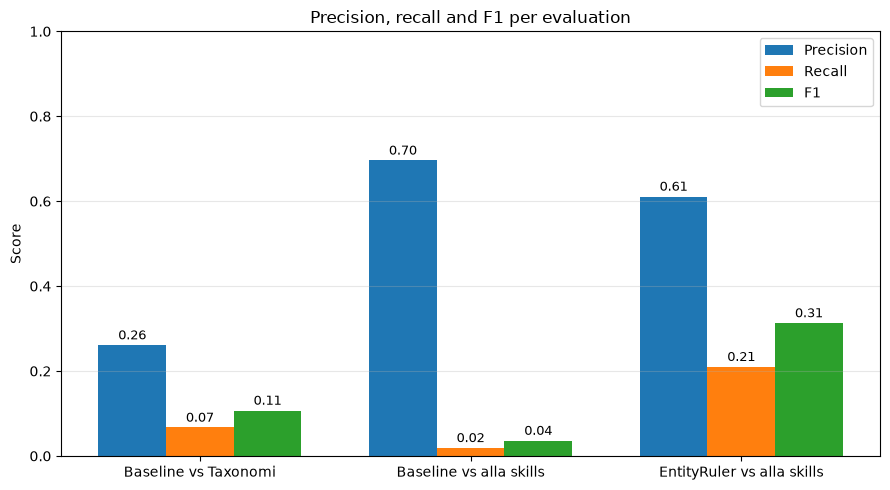

In [ ]:
# visualisering av precision, recall och f1 för de olika metoderna
import matplotlib.pyplot as plt
import numpy as np
 
metrics = ["precision", "recall", "f1"]
methods = results_df["method"].tolist()
 
x = np.arange(len(methods))      
width = 0.25                     
 
fig, ax = plt.subplots(figsize=(9, 5))
 
for i, metric in enumerate(metrics):
    values = results_df[metric].tolist()
    bars = ax.bar(x + i * width, values, width, label=metric.capitalize())
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)   
 
ax.set_xticks(x + width)         
ax.set_xticklabels(methods)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Precision, recall and F1 per evaluation")
ax.legend()
ax.grid(axis="y", alpha=0.3)
 
plt.tight_layout()
plt.show()